# SMS Spam Detection — Tuned Pipeline

This notebook builds and tunes a machine learning system to classify SMS
messages as Spam or Ham, using cleaned/stemmed text, TF-IDF, and
hyperparameter search over three classifiers.

## Pipeline
1. Text cleaning (URLs/emails/numbers normalized, punctuation stripped, stemmed)
2. TF-IDF vectorization (unigrams + bigrams)
3. GridSearchCV over Naive Bayes, Logistic Regression, and Linear SVM
4. Linear SVM calibrated (`CalibratedClassifierCV`) for probability scores
5. Best pipeline saved as a single artifact (`models/spam_pipeline.pkl`)


In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from preprocessing import clean_text

## Load dataset

In [2]:
df = pd.read_csv("../data/spam.csv")
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
df.shape

(5572, 2)

## Clean the dataset

In [4]:
df = df[["label", "message"]].copy()
df = df.dropna()
df = df.drop_duplicates()
df.shape

(5169, 2)

## Preview the text-cleaning function

In [5]:
sample = "URGENT!! Call 08712345678 now, visit http://scam.example.com to CLAIM your prize!!!"
print("Before:", sample)
print("After: ", clean_text(sample))

Before: URGENT!! Call 08712345678 now, visit http://scam.example.com to CLAIM your prize!!!
After:  urgent call numtoken now visit urltoken to claim your prize


## Visualize class distribution

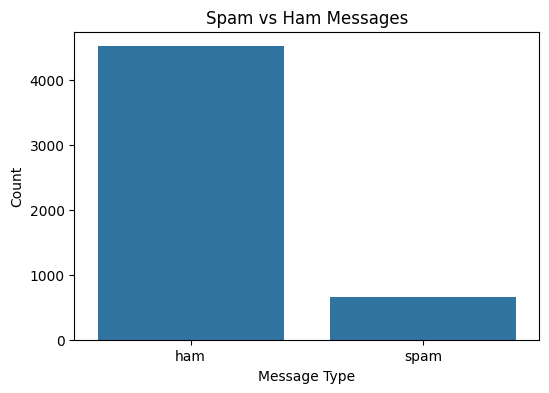

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

## Convert labels to numeric and split

In [7]:
df["label_encoded"] = df["label"].map({"ham": 0, "spam": 1})

X = df["message"]
y = df["label_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Build & tune pipelines

Each pipeline does cleaning (inside the TF-IDF preprocessor) → vectorization →
classification, so it can be saved and reused as a single object.

In [8]:
def make_vectorizer():
    return TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), sublinear_tf=True)

param_grids = {
    "Naive Bayes": (
        Pipeline([("tfidf", make_vectorizer()), ("clf", MultinomialNB())]),
        {"tfidf__max_features": [3000, 5000], "clf__alpha": [0.1, 0.5, 1.0]},
    ),
    "Logistic Regression": (
        Pipeline([
            ("tfidf", make_vectorizer()),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
        ]),
        {"tfidf__max_features": [3000, 5000], "clf__C": [1, 5, 10]},
    ),
    "Linear SVM": (
        Pipeline([
            ("tfidf", make_vectorizer()),
            ("clf", CalibratedClassifierCV(
                LinearSVC(class_weight="balanced", dual="auto"), cv=3
            )),
        ]),
        {"tfidf__max_features": [3000, 5000], "clf__estimator__C": [0.5, 1, 5]},
    ),
}

In [9]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
    }

results = []
fitted = {}
best_params_log = {}

for name, (pipe, grid) in param_grids.items():
    search = GridSearchCV(pipe, grid, scoring="f1", cv=5, n_jobs=-1)
    search.fit(X_train, y_train)

    best_pipe = search.best_estimator_
    pred = best_pipe.predict(X_test)

    results.append(evaluate(name, y_test, pred))
    fitted[name] = best_pipe
    best_params_log[name] = search.best_params_

    print(f"{name} — best params: {search.best_params_}")
    print(classification_report(y_test, pred, target_names=["Ham", "Spam"]))

Naive Bayes — best params: {'clf__alpha': 0.1, 'tfidf__max_features': 5000}
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.97      0.92      0.94       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



Logistic Regression — best params: {'clf__C': 5, 'tfidf__max_features': 5000}
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.97      0.94      0.95       131

    accuracy                           0.99      1034
   macro avg       0.98      0.97      0.97      1034
weighted avg       0.99      0.99      0.99      1034



Linear SVM — best params: {'clf__estimator__C': 1, 'tfidf__max_features': 5000}
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.98      0.94      0.96       131

    accuracy                           0.99      1034
   macro avg       0.98      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



## Compare models

In [10]:
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.985493,0.967742,0.916031,0.941176
1,Logistic Regression,0.988395,0.968504,0.938931,0.953488
2,Linear SVM,0.989362,0.976190,0.938931,0.957198


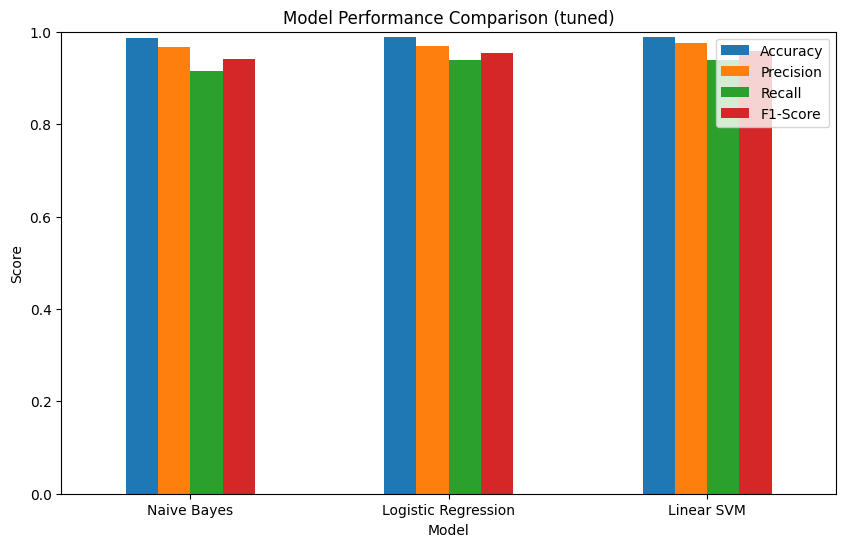

In [11]:
results_df.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1-Score"],
    kind="bar",
    figsize=(10, 6)
)
plt.title("Model Performance Comparison (tuned)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## Confusion matrix — best model

Best model: Linear SVM


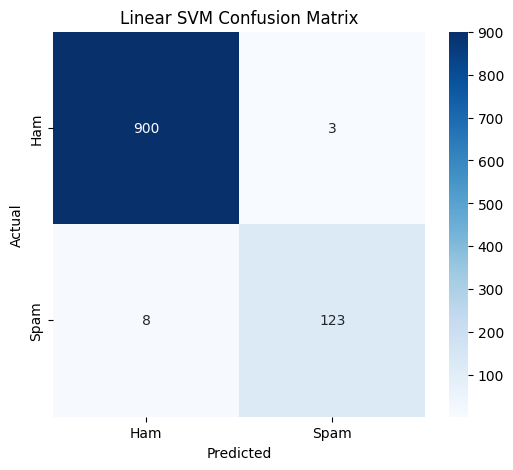

In [12]:
best_row = results_df.loc[results_df["F1-Score"].idxmax()]
best_name = best_row["Model"]
best_pipeline = fitted[best_name]
print("Best model:", best_name)

cm = confusion_matrix(y_test, best_pipeline.predict(X_test))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{best_name} Confusion Matrix")
plt.show()

## Test with confidence scores

In [13]:
test_messages = [
    "Hey, are you coming to class tomorrow?",
    "Congratulations! You have won a $1000 prize. Click now!",
    "Can you send me the assignment?",
    "URGENT! Claim your FREE reward today!"
]

proba = best_pipeline.predict_proba(test_messages)

for message, p in zip(test_messages, proba):
    spam_prob = p[1]
    label = "SPAM" if spam_prob >= 0.5 else "HAM"
    print(f"[{label} {spam_prob:.0%}] {message}")

[HAM 0%] Hey, are you coming to class tomorrow?
[SPAM 97%] Congratulations! You have won a $1000 prize. Click now!
[HAM 0%] Can you send me the assignment?
[SPAM 81%] URGENT! Claim your FREE reward today!


## Save the best pipeline

In [14]:
import joblib
import json

joblib.dump(best_pipeline, "../models/spam_pipeline.pkl")

with open("../models/results.json", "w") as f:
    json.dump({
        "results": results_df.to_dict(orient="records"),
        "best_model": best_name,
        "best_params": best_params_log[best_name],
        "confusion_matrix": cm.tolist(),
        "dataset_size": len(df),
        "test_size": len(y_test),
    }, f, indent=2)

print("Saved models/spam_pipeline.pkl and models/results.json")

Saved models/spam_pipeline.pkl and models/results.json
